# Lab 6 · Entanglement and the CHSH test

**Levels 5–6 · Quantum information → Quantum causal models** · Prerequisite lessons: L5-04 (Tensor products and entanglement), L5-08 (Bell correlations and the CHSH test), L6-01 (Quantum common causes).

**What you'll learn**

- Why each half of a Bell state, on its own, is maximally mixed.
- How the CHSH value $S$ depends on the measurement angles. Why local hidden-variable models obey $|S|\le 2$ while quantum states reach $2\sqrt2$ [@bell; @chsh].
- How the Werner family shows that *entangled* and *violates CHSH* are different properties.
- Why Bell correlations still cannot be used to send a signal.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/06-entanglement-bell.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math, itertools
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from qcai import science as s
from qcai.viz import show

SQ2 = math.sqrt(2)
np.set_printoptions(precision=4, suppress=True)

## 1 · Bell states and their reduced states

The four Bell states are

$$
|\Phi^\pm\rangle=\tfrac{1}{\sqrt2}(|00\rangle\pm|11\rangle),\qquad |\Psi^\pm\rangle=\tfrac{1}{\sqrt2}(|01\rangle\pm|10\rangle).
$$

The reduced state of qubit A is $\rho_A=\operatorname{Tr}_B\,\rho_{AB}$. It is what Alice can learn if she ignores Bob.

:::{note} Predict
The global state $|\Phi^+\rangle$ is pure (purity 1). What do you expect for the purity and entropy of Alice's reduced state?
:::

In [3]:
names = ["phi+", "phi-", "psi+", "psi-"]
B = {n: s.bell_state(n) for n in names}
gram = np.array([[np.vdot(B[a], B[b]) for b in names] for a in names])
assert np.allclose(gram, np.eye(4))                 # orthonormal basis

for n in names:
    rho = s.dm(B[n])
    for keep in (0, 1):
        red = s.partial_trace(rho, keep)
        assert np.allclose(red, np.eye(2) / 2)        # maximally mixed half
        assert abs(s.von_neumann_entropy(red) - 1) < 1e-12
    assert abs(s.purity(rho) - 1) < 1e-12
    print(f"{n:5s}: global purity {s.purity(rho):.3f}; reduced purity {s.purity(s.partial_trace(rho, 0)):.3f}; "
          f"reduced entropy {s.von_neumann_entropy(s.partial_trace(rho, 0)):.3f} bit; concurrence {s.concurrence(rho):.3f}")

# contrast: a product state has pure halves and zero concurrence
prod = s.dm(np.kron(s.ket(0.7, 0.2), s.ket(2.0, 1.0)))
assert abs(s.purity(s.partial_trace(prod, 0)) - 1) < 1e-12 and s.concurrence(prod) < 1e-6   # zero up to round-off in the eigenvalue square roots

phi+ : global purity 1.000; reduced purity 0.500; reduced entropy 1.000 bit; concurrence 1.000
phi- : global purity 1.000; reduced purity 0.500; reduced entropy 1.000 bit; concurrence 1.000
psi+ : global purity 1.000; reduced purity 0.500; reduced entropy 1.000 bit; concurrence 1.000
psi- : global purity 1.000; reduced purity 0.500; reduced entropy 1.000 bit; concurrence 1.000


**Explain.** The whole is pure, but each half has purity $1/2$ and entropy 1 bit, the maximum for a qubit. All the information is in the *correlations*. None is in the parts. A product state is the opposite: pure halves, zero concurrence.

## 2 · CHSH value versus measurement angle

Alice measures $A_x=\cos a_x\,Z+\sin a_x\,X$ for settings $x\in\{0,1\}$, and Bob measures $B_y$ the same way. The CHSH combination is

$$
S = E(a_0,b_0)+E(a_0,b_1)+E(a_1,b_0)-E(a_1,b_1),\qquad E(a,b)=\operatorname{Tr}[\rho\,(A\otimes B)].
$$

We fix Alice at $a_0=0$, $a_1=\pi/2$ and give Bob $b_0=\beta$, $b_1=-\beta$. Take the Werner state $\rho_v=v|\Phi^+\rangle\langle\Phi^+|+(1-v)I/4$. Its closed form is $S(\beta)=2v(\cos\beta+\sin\beta)=2\sqrt2\,v\sin(\beta+\pi/4)$.

:::{note} Predict
At which $\beta$ is $S$ largest for $v=1$? How small must $v$ be before no $\beta$ exceeds the classical bound 2?
:::

In [4]:
betas = np.linspace(-math.pi, math.pi, 361)   # 1-degree steps, includes 45 degrees
vs = np.round(np.linspace(0.3, 1.0, 15), 2)

def S_curve(v):
    rho = s.werner(v)
    return np.array([s.chsh_value(rho, 0, math.pi / 2, b, -b) for b in betas])

curves = {v: S_curve(v) for v in vs}
for v in vs:
    assert np.allclose(curves[v], 2 * SQ2 * v * np.sin(betas + math.pi / 4), atol=1e-12)   # closed form
best = betas[np.argmax(curves[1.0])]
print(f"v = 1: max S on the grid = {curves[1.0].max():.6f} at beta = {math.degrees(best):.1f} deg; 2*sqrt(2) = {2*SQ2:.6f}")
assert abs(curves[1.0].max() - 2 * SQ2) < 1e-9 and abs(best - math.pi / 4) < 1e-9
# the engine's closed-form bell(v) uses the same optimal settings
for v in vs:
    assert abs(s.bell(float(v)) - s.chsh_value(s.werner(float(v)), 0, math.pi / 2, math.pi / 4, -math.pi / 4)) < 1e-12

deg = np.degrees(betas)
v0 = 1.0
fig = go.Figure([
    go.Scatter(x=deg, y=curves[v0], mode="lines", name="S(β), Werner state", line=dict(color="crimson", width=3)),
    go.Scatter(x=[-180, 180, None, -180, 180], y=[2, 2, None, -2, -2], mode="lines", name="local bound |S| = 2",
               line=dict(color="black", dash="dash")),
    go.Scatter(x=[-180, 180, None, -180, 180], y=[2 * SQ2, 2 * SQ2, None, -2 * SQ2, -2 * SQ2], mode="lines",
               name="Tsirelson bound 2√2", line=dict(color="gray", dash="dot")),
])
steps = [dict(method="restyle", label=f"{v:.2f}", args=[{"y": [curves[v]]}, [0]]) for v in vs]
fig.update_layout(height=480, title="CHSH value as Bob rotates his settings (a₀=0, a₁=90°, b₀=β, b₁=−β)",
                  xaxis_title="β (degrees)", yaxis_title="S", yaxis_range=[-3.1, 3.1],
                  sliders=[dict(active=len(vs) - 1, currentvalue=dict(prefix="visibility v = "), pad=dict(t=50), steps=steps)])
show(fig)

v = 1: max S on the grid = 2.828427 at beta = 45.0 deg; 2*sqrt(2) = 2.828427


**Explain.** For $v=1$ the maximum is at $\beta=\pi/4$ and equals $2\sqrt2$. The peak scales linearly with $v$. So for *this* choice of settings, the curve stops crossing the classical bound once $2\sqrt2\,v\le 2$, that is, $v\le 1/\sqrt2$. Section 4 shows that no other choice does better.

## 3 · Where do the bounds 2 and $2\sqrt2$ come from?

Start with local hidden variables. Suppose a classical common cause $\lambda$ fixes every outcome in advance: $A_x(\lambda),B_y(\lambda)\in\{\pm1\}$. There are only $2^4=16$ deterministic assignments, and any local model is a probabilistic mixture of them. $S$ is linear in the probabilities. Its maximum over mixtures is therefore its maximum over the 16 assignments [@bell; @chsh].

Now the quantum case. For two qubits, the largest $S$ over all measurement directions is $2\sqrt{t_1+t_2}$. Here $t_1,t_2$ are the two largest eigenvalues of $T^\top T$, and $T_{ij}=\operatorname{Tr}[\rho\,\sigma_i\otimes\sigma_j]$. This is the Horodecki formula, implemented in `horodecki_max_chsh`. The singular values of $T$ are at most 1, so $S\le 2\sqrt2$.

In [5]:
# Enumerate all 16 deterministic local strategies
vals = []
for A0, A1, B0, B1 in itertools.product([1, -1], repeat=4):
    vals.append(A0 * B0 + A0 * B1 + A1 * B0 - A1 * B1)
print("CHSH values of the 16 deterministic strategies:", sorted(set(vals)))
assert max(abs(x) for x in vals) == 2

# Random two-qubit states never exceed 2*sqrt(2); Bell states reach it
g = np.random.default_rng(1)
def random_state(rank):
    G = g.normal(size=(4, rank)) + 1j * g.normal(size=(4, rank))
    r = G @ G.conj().T
    return r / np.trace(r)
mx = [s.horodecki_max_chsh(random_state(int(g.integers(1, 5)))) for _ in range(2000)]
print(f"largest max-CHSH among 2000 random states: {max(mx):.4f}  (bound {2*SQ2:.4f})")
assert max(mx) <= 2 * SQ2 + 1e-9
for n in names:
    assert abs(s.horodecki_max_chsh(s.dm(B[n])) - 2 * SQ2) < 1e-12

CHSH values of the 16 deterministic strategies: [-2, 2]


largest max-CHSH among 2000 random states: 2.8183  (bound 2.8284)


## 4 · Werner states: entangled without violating CHSH

For the Werner family two closed forms hold:

- concurrence $C(\rho_v)=\max\!\left(0,\tfrac{3v-1}{2}\right)$, so the state is entangled exactly when $v>1/3$;
- maximal CHSH value $S_{\max}(\rho_v)=2\sqrt2\,v$, so CHSH is violated exactly when $v>1/\sqrt2$.

In the window $1/3<v\le 1/\sqrt2$ the state is entangled. Yet no choice of measurement directions violates CHSH. The code checks both formulas against the engine. It checks the entanglement threshold a second way with the partial transpose: a two-qubit state is entangled exactly when its partial transpose has a negative eigenvalue.

:::{note} Predict
At $v=0.5$, is the Werner state entangled? Does it violate CHSH?
:::

In [6]:
vgrid = np.linspace(0, 1, 201)
conc = np.array([s.concurrence(s.werner(float(v))) for v in vgrid])
smax = np.array([s.horodecki_max_chsh(s.werner(float(v))) for v in vgrid])
assert np.allclose(conc, np.maximum(0, (3 * vgrid - 1) / 2), atol=1e-9)
assert np.allclose(smax, 2 * SQ2 * vgrid, atol=1e-9)

def partial_transpose(rho):
    return rho.reshape(2, 2, 2, 2).transpose(0, 3, 2, 1).reshape(4, 4)
min_pt = np.array([np.linalg.eigvalsh(partial_transpose(s.werner(float(v)))).min() for v in vgrid])
assert np.allclose(min_pt, (1 - 3 * vgrid) / 4, atol=1e-12)
assert np.all((min_pt < -1e-12) == (conc > 1e-12))           # PPT test and concurrence agree on the grid

lo, hi = 1 / 3, 1 / SQ2
w = s.werner(0.5)
print(f"v = 0.5: concurrence = {s.concurrence(w):.4f}, max CHSH = {s.horodecki_max_chsh(w):.4f}")
assert s.concurrence(w) > 0 and s.horodecki_max_chsh(w) < 2
print(f"window: {lo:.4f} < v <= {hi:.4f}")

fig = go.Figure([
    go.Scatter(x=vgrid, y=conc, name="concurrence (3v−1)/2", line=dict(color="#4c78a8", width=3), yaxis="y"),
    go.Scatter(x=vgrid, y=smax, name="max CHSH 2√2·v", line=dict(color="crimson", width=3), yaxis="y2"),
    go.Scatter(x=[0, 1], y=[2, 2], name="local bound 2", line=dict(color="black", dash="dash"), yaxis="y2"),
    go.Scatter(x=[0.5], y=[s.concurrence(w)], mode="markers", marker=dict(size=12, color="#4c78a8"), name="selected v (concurrence)", yaxis="y"),
    go.Scatter(x=[0.5], y=[s.horodecki_max_chsh(w)], mode="markers", marker=dict(size=12, color="crimson"), name="selected v (max CHSH)", yaxis="y2"),
])
steps = []
for v in np.round(np.linspace(0, 1, 21), 2):
    wv = s.werner(float(v))
    steps.append(dict(method="restyle", label=f"{v:.2f}",
                      args=[{"x": [[v], [v]], "y": [[s.concurrence(wv)], [s.horodecki_max_chsh(wv)]]}, [3, 4]]))
fig.update_layout(
    height=500, title="Werner state: entanglement vs CHSH violation",
    xaxis=dict(title="visibility v", range=[0, 1]),
    yaxis=dict(title="concurrence", range=[-0.05, 1.05]),
    yaxis2=dict(title="max CHSH", overlaying="y", side="right", range=[-0.1, 3.0]),
    shapes=[dict(type="rect", xref="x", yref="paper", x0=lo, x1=hi, y0=0, y1=1, fillcolor="gold", opacity=0.2, line_width=0)],
    annotations=[dict(x=(lo + hi) / 2, y=1.02, xref="x", yref="paper", text="entangled, no CHSH violation", showarrow=False)],
    legend=dict(x=0.01, y=0.99), sliders=[dict(active=10, currentvalue=dict(prefix="v = "), pad=dict(t=50), steps=steps)])
show(fig)

v = 0.5: concurrence = 0.2500, max CHSH = 1.4142
window: 0.3333 < v <= 0.7071


**Explain.** At $v=0.5$ the concurrence is positive (entangled) but $S_{\max}=\sqrt2<2$. So "entangled" does not imply "violates CHSH". The other direction holds: any CHSH violation certifies entanglement, because separable states obey $|S|\le 2$. Under the Bell-test assumptions this holds even for uncharacterised devices. The computation says nothing about other Bell inequalities or more general measurements. It covers CHSH with projective $\pm1$ measurements on each qubit.

## 5 · No signalling

Bell correlations cannot carry a message. Alice's outcome statistics must not depend on Bob's *choice* of setting. For any state and any local measurements,

$$
p(a\mid x,y)=\sum_b p(a,b\mid x,y)=\operatorname{Tr}\!\left[\rho_A\,\Pi^{A}_{a|x}\right],
$$

which contains no $y$. The code checks this for random states and random angles.

In [7]:
def proj(t, outcome):
    return 0.5 * (s.I2 + outcome * (math.cos(t) * s.Z + math.sin(t) * s.X))

def joint(rho, a, b):
    """p(alpha, beta) for alpha, beta in {+1, -1}, as a 2x2 table."""
    return np.array([[np.real(np.trace(rho @ s.kron(proj(a, oa), proj(b, ob)))) for ob in (1, -1)] for oa in (1, -1)])

g = np.random.default_rng(2)
worst = 0.0
for _ in range(300):
    rho = random_state(int(g.integers(1, 5)))
    a, b1, b2 = g.uniform(0, 2 * math.pi, 3)
    pa_1, pa_2 = joint(rho, a, b1).sum(axis=1), joint(rho, a, b2).sum(axis=1)
    worst = max(worst, np.abs(pa_1 - pa_2).max())
    # Alice's marginal equals the reduced-state prediction
    rA = s.partial_trace(rho, 0)
    assert np.allclose(pa_1, [np.real(np.trace(rA @ proj(a, o))) for o in (1, -1)], atol=1e-12)
print(f"largest change in Alice's marginal when Bob switches setting: {worst:.2e}\n", end="")
assert worst < 1e-12

# Same check for the engine's closed-form Bell distribution
for a in np.linspace(0, math.pi, 7):
    for b in np.linspace(0, math.pi, 7):
        p = s.bell_distribution(a, b, 0.8)
        assert abs(p[0] + p[1] - 0.5) < 1e-12 and abs(p[0] + p[2] - 0.5) < 1e-12

largest change in Alice's marginal when Bob switches setting: 2.22e-16


A static view: the four joint tables at the optimal CHSH settings for $|\Phi^+\rangle$. In every panel, each row sum (Alice's marginal) is $1/2$, even though the correlations change sign between panels.

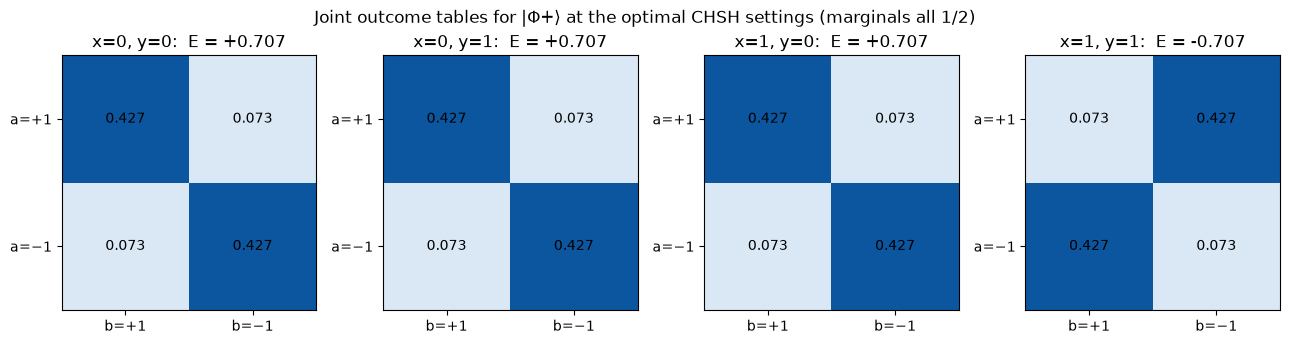

In [8]:
A_set, B_set = [0, math.pi / 2], [math.pi / 4, -math.pi / 4]
phi = s.dm(B["phi+"])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for k, (x, y) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1)]):
    P = joint(phi, A_set[x], B_set[y])
    assert np.allclose(P.sum(axis=1), 0.5) and np.allclose(P.sum(axis=0), 0.5)
    E = P[0, 0] + P[1, 1] - P[0, 1] - P[1, 0]
    ax = axes[k]
    ax.imshow(P, vmin=0, vmax=0.5, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{P[i, j]:.3f}", ha="center", va="center")
    ax.set_xticks([0, 1], ["b=+1", "b=−1"]); ax.set_yticks([0, 1], ["a=+1", "a=−1"])
    ax.set_title(f"x={x}, y={y}:  E = {E:+.3f}")
plt.suptitle("Joint outcome tables for |Φ+⟩ at the optimal CHSH settings (marginals all 1/2)")
plt.tight_layout(); plt.show()
S_opt = sum(sgn * (joint(phi, A_set[x], B_set[y]) * np.array([[1, -1], [-1, 1]])).sum()
            for (x, y), sgn in zip([(0, 0), (0, 1), (1, 0), (1, 1)], [1, 1, 1, -1]))
assert abs(S_opt - 2 * SQ2) < 1e-12

## Going deeper

Write the CHSH operator $\mathcal B = A_0\otimes(B_0+B_1)+A_1\otimes(B_0-B_1)$. With $\pm1$-valued observables, $\mathcal B^2 = 4\,I - [A_0,A_1]\otimes[B_0,B_1]$. Each commutator has operator norm at most 2, so $\|\mathcal B^2\|\le 8$ and $|S|\le 2\sqrt2$ (Tsirelson's bound). In a hidden-variable model the observables are numbers, so they commute. The second term then vanishes and $|S|\le2$. The next cell checks the identity for the optimal settings.

Read causally (lesson L6-01), the Bell scenario is a graph with a common cause $\Lambda\to A$, $\Lambda\to B$ and free settings $X\to A$, $Y\to B$. Under the Bell assumptions, a CHSH violation rules out a *classical* $\Lambda$. It is consistent with a *quantum* common cause [@allen].

In [9]:
def obs(t):
    return math.cos(t) * s.Z + math.sin(t) * s.X
A0, A1, B0_, B1_ = obs(0), obs(math.pi / 2), obs(math.pi / 4), obs(-math.pi / 4)
Bop = s.kron(A0, B0_ + B1_) + s.kron(A1, B0_ - B1_)
comm = lambda P, Q: P @ Q - Q @ P
assert np.allclose(Bop @ Bop, 4 * np.eye(4) - s.kron(comm(A0, A1), comm(B0_, B1_)))
assert abs(np.linalg.eigvalsh(Bop).max() - 2 * SQ2) < 1e-9
print("max eigenvalue of the CHSH operator:", np.linalg.eigvalsh(Bop).max())

max eigenvalue of the CHSH operator: 2.8284271247461903


## Exercises

:::{admonition} Exercise: :label: lab06-ex1
:class: tip
At what Werner visibility $v^{\star}$ does the maximal CHSH value equal exactly 2? What is the concurrence there?
:::

:::{dropdown} Solution
$2\sqrt2\,v^{\star}=2$ gives $v^{\star}=1/\sqrt2\approx0.7071$. The concurrence is $(3/\sqrt2-1)/2\approx0.5607$. The state is substantially entangled, yet there is no CHSH violation.
:::

:::{admonition} Exercise: :label: lab06-ex2
:class: tip
For the singlet $|\Psi^-\rangle$, compute $E(a,b)$ for measurements in the $XZ$ plane, and the CHSH value at Alice $0,\pi/2$ and Bob $\pi/4,-\pi/4$.
:::

:::{dropdown} Solution
For $|\Psi^-\rangle$, $\langle XX\rangle=\langle ZZ\rangle=-1$ and $\langle XZ\rangle=\langle ZX\rangle=0$, so $E(a,b)=-\cos(a-b)$ and $S=-2\sqrt2$. The magnitude still reaches the Tsirelson bound. Flipping the sign of one of Bob's outcomes gives $+2\sqrt2$.
:::

:::{admonition} Exercise: :label: lab06-ex3
:class: tip
Show without enumeration that a deterministic local strategy has $S\in\{-2,+2\}$.
:::

:::{dropdown} Solution
$S=A_0(B_0+B_1)+A_1(B_0-B_1)$. With $B_0,B_1=\pm1$, one bracket is $\pm2$ and the other is $0$. So $S=\pm2$.
:::

## Check yourself

In [10]:
v_star = 1 / SQ2
assert abs(s.horodecki_max_chsh(s.werner(v_star)) - 2) < 1e-9
assert abs(s.concurrence(s.werner(v_star)) - (3 / SQ2 - 1) / 2) < 1e-9
print(f"v* = {v_star:.4f}, concurrence there = {s.concurrence(s.werner(v_star)):.4f}")
singlet = s.dm(B["psi-"])
for a in np.linspace(0, math.pi, 5):
    for b in np.linspace(0, math.pi, 5):
        assert abs(np.real(np.trace(singlet @ s.kron(obs(a), obs(b)))) + math.cos(a - b)) < 1e-12
assert abs(s.chsh_value(singlet, 0, math.pi / 2, math.pi / 4, -math.pi / 4) + 2 * SQ2) < 1e-12
for A0v, A1v, B0v, B1v in itertools.product([1, -1], repeat=4):
    assert A0v * (B0v + B1v) + A1v * (B0v - B1v) in (-2, 2)
print("All checks passed.")

v* = 0.7071, concurrence there = 0.5607
All checks passed.


## Limits of this model

The bound 2 rests on assumptions: locality, measurement (setting) independence, and fair sampling. We assume them; we do not test them here. A real Bell experiment must address each one [@bell; @chsh].

The states are ideal. The Werner family is a convenient one-parameter model of white noise. Real noise is rarely isotropic.

The measurements lie in one plane. `chsh_value` uses settings in the $XZ$ plane. That is enough for these states, and `horodecki_max_chsh` covers all directions.

We test one inequality. Not violating CHSH does not show that a state admits a local model for every possible measurement scenario.

The expectations are exact. We used exact probabilities. A finite experiment estimates $S$ with statistical error, as Lab 5 showed for one qubit.